## ***Clustering of image data using DBSCAN vs. K-means***

---






Prikupljanje podataka

---

- [Dataset](https://www.kaggle.com/datasets/bhaveshmittal/melanoma-cancer-dataset)

- 200 podataka po klasifikaciji (benigno/maligno)

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import cv2
from google.colab.patches import cv2_imshow
from google.colab import drive

drive.mount('/content/drive')

train_data_path = '/content/drive/MyDrive/SU/Projekt/melanom/train'
benign_path = train_data_path + '/Benign'
malignant_path = train_data_path + '/Malignant'
test_data_path = '/content/drive/MyDrive/SU/Projekt/melanom/test'
benign_test_path = test_data_path + '/Benign'
malignant_test_path = test_data_path + '/Malignant'

print(len(os.listdir(benign_path)))
print(len(os.listdir(malignant_path)))

Mounted at /content/drive
200
200


Prikaz uzorka iz dataset-a

---



Benign Image:



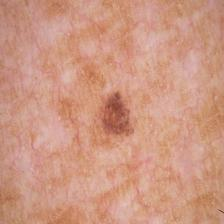


Malignant Image:



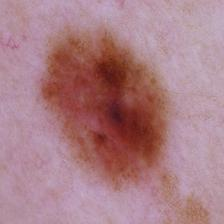

In [ ]:
# Dohvaćanje mapa
benign_files = os.listdir(benign_path)
malignant_files = os.listdir(malignant_path)


benign_image_path = os.path.join(benign_path, benign_files[97])
malignant_image_path = os.path.join(malignant_path, malignant_files[1])

# Učitavanje slika
benign_image = cv2.imread(benign_image_path)
malignant_image = cv2.imread(malignant_image_path)

print("Benign Image:\n")
cv2_imshow(benign_image)

print("\nMalignant Image:\n")
cv2_imshow(malignant_image)

K-Means i primjer izlaza

---



In [ ]:
def self_kmeans(X, n_clusters, max_iter=100, tol=1e-4, random_state=42):
    # Inicijalizacija random centara
    np.random.seed(random_state)
    centroids = X[np.random.choice(X.shape[0], n_clusters, replace=False)]

    for _ in range(max_iter):
        # Podjela podataka prema najbližim centrima
        distances = np.sqrt(((X[:, np.newaxis] - centroids) ** 2).sum(axis=-1))
        labels = np.argmin(distances, axis=1)

        # Ažuriranje centara
        new_centroids = np.array([X[labels == i].mean(axis=0) for i in range(n_clusters)])

        # Provjera konvergencije
        if np.max(np.abs(new_centroids - centroids)) < tol:
            break

        centroids = new_centroids

    return labels, centroids

Primjer izlaza

---



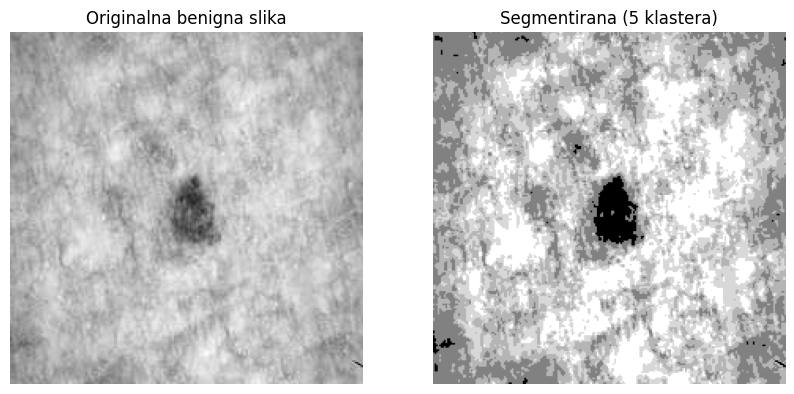

In [ ]:
benign_image_gray = cv2.cvtColor(benign_image, cv2.COLOR_BGR2GRAY)
malignant_image_gray = cv2.cvtColor(malignant_image, cv2.COLOR_BGR2GRAY)

# Ručno K-Means klasteriranje s 5 klastera
labels, centroids = self_kmeans(benign_image_gray.reshape(-1, 1), n_clusters=5)

# Preoblikovanje klasteriranih podataka slike
segmented_image_data = centroids[labels].reshape(benign_image_gray.shape)

# Pretvorba klasteriranih podataka slike natrag u sliku
segmented_image = segmented_image_data.astype(np.uint8)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(benign_image_gray, cmap='gray')
plt.title('Originalna benigna slika')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(segmented_image, cmap='gray')
plt.title('Segmentirana (5 klastera)')
plt.axis('off')
plt.show()

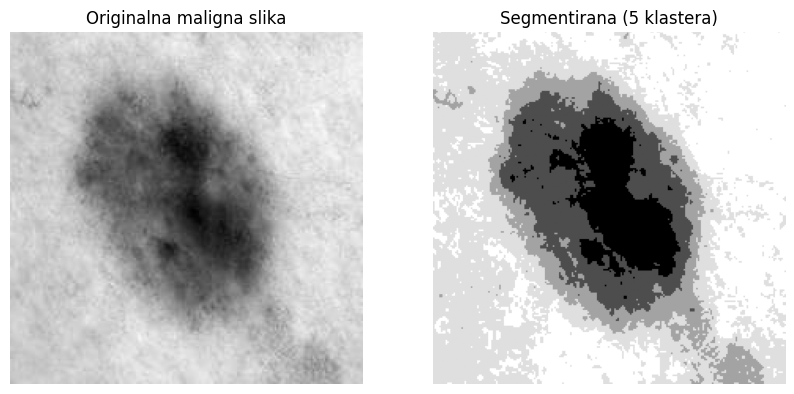

In [ ]:
labels, centroids = self_kmeans(malignant_image_gray.reshape(-1, 1), n_clusters=5)

segmented_image_data = centroids[labels].reshape(malignant_image_gray.shape)

segmented_image = segmented_image_data.astype(np.uint8)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(malignant_image_gray, cmap='gray')
plt.title('Originalna maligna slika')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(segmented_image, cmap='gray')
plt.title('Segmentirana (5 klastera)')
plt.axis('off')
plt.show()

Pronalazak optimalnog broja klastera

---

- Elbow Method
- Silhouette Score


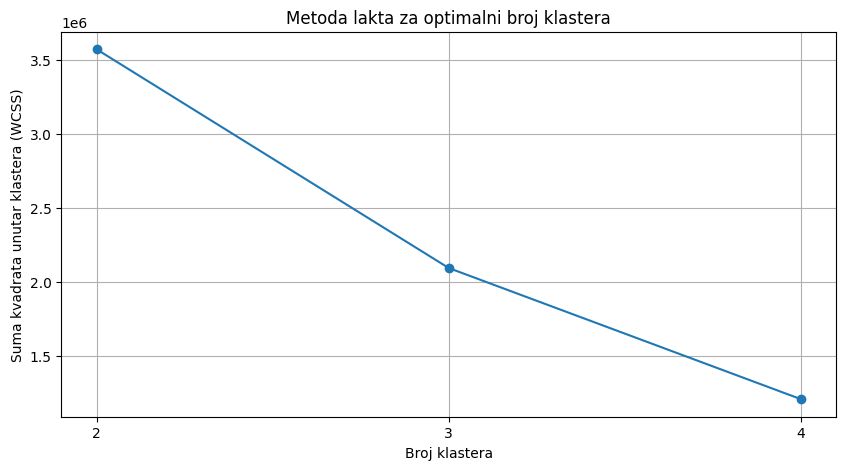

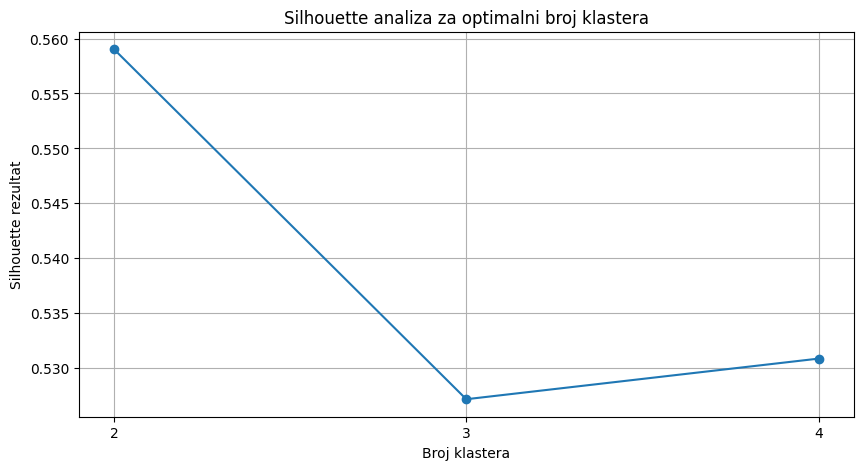

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Liste za spremanje WCSS-a i silhouette rezultata
wcss = []
silhouette_scores = []

# Raspon klastera za testiranje
clusters_range = range(2, 5)

for n_clusters in clusters_range:
    kmeans = KMeans(n_clusters=n_clusters, random_state=42)
    kmeans.fit(benign_image_gray.reshape(-1,1))

    wcss.append(kmeans.inertia_)

    silhouette_scores.append(silhouette_score(benign_image_gray.reshape(-1,1), kmeans.labels_))

plt.figure(figsize=(10, 5))
plt.plot(clusters_range, wcss, marker='o')
plt.title('Metoda lakta za optimalni broj klastera')
plt.xlabel('Broj klastera')
plt.ylabel('Suma kvadrata unutar klastera (WCSS)')
plt.xticks(clusters_range)
plt.grid(True)
plt.show()

# Nacrtaj silhouette rezultate u odnosu na broj klastera
plt.figure(figsize=(10, 5))
plt.plot(clusters_range, silhouette_scores, marker='o')
plt.title('Silhouette analiza za optimalni broj klastera')
plt.xlabel('Broj klastera')
plt.ylabel('Silhouette rezultat')
plt.xticks(clusters_range)
plt.grid(True)
plt.show()

Pretprocesiranje podataka

---

- Segmentacija slike koristeći K-Means

In [ ]:
import os
import cv2
import numpy as np
import shutil

def primjena_kmeans_a_na_direktorij(ulazni_direktorij, izlazni_direktorij, n_clusters):

    # Očisti izlazni direktorij ako postoji
    if os.path.exists(izlazni_direktorij):
        shutil.rmtree(izlazni_direktorij)
    os.makedirs(izlazni_direktorij)  # Stvori direktorij nakon brisanja

    for naziv_datoteke in os.listdir(ulazni_direktorij):
        if naziv_datoteke.endswith(('.jpg', '.jpeg', '.png')):
            putanja_slike = os.path.join(ulazni_direktorij, naziv_datoteke)
            slika = cv2.imread(putanja_slike)

            if slika is not None:
                siva_slika = cv2.cvtColor(slika, cv2.COLOR_BGR2GRAY)

                labels, centroids = self_kmeans(siva_slika.reshape(-1, 1), n_clusters=n_clusters)

                segmentirani_podaci_slike = centroids[labels].reshape(siva_slika.shape)
                segmentirana_slika = segmentirani_podaci_slike.astype(np.uint8)

                # Spremanje SAMO segmentirane slike
                cv2.imwrite(os.path.join(izlazni_direktorij, f'segmentirana_{naziv_datoteke}'), segmentirana_slika)
            else:
                print(f"Nije moguće učitati sliku: {putanja_slike}")


benign_path = "/content/drive/MyDrive/SU/Projekt/melanom/train/Benign"
malignant_path = "/content/drive/MyDrive/SU/Projekt/melanom/train/Malignant"

benigne_segmentirane_putanje = '/content/drive/MyDrive/SU/Projekt/melanom/train/Seg_benign'
maligne_segmentirane_putanje = '/content/drive/MyDrive/SU/Projekt/melanom/train/Seg_malignant'

broj_klastera = 2

primjena_kmeans_a_na_direktorij(benign_path, benigne_segmentirane_putanje, broj_klastera)
primjena_kmeans_a_na_direktorij(malignant_path, maligne_segmentirane_putanje, broj_klastera)


print("Segmentacija slika završena.")

print(f"Broj benignih segmentiranih slika: {len(os.listdir(benigne_segmentirane_putanje))}")
print(f"Broj malignih segmentiranih slika: {len(os.listdir(maligne_segmentirane_putanje))}")

<ipython-input-4-d674b7ca1ffb>:12: RuntimeWarning: Mean of empty slice.
  new_centroids = np.array([X[labels == i].mean(axis=0) for i in range(n_clusters)])


Segmentacija slika završena.
Broj benignih segmentiranih slika: 200
Broj malignih segmentiranih slika: 200


Ekstrakcija značajki

---



In [ ]:
from keras.applications.resnet50 import preprocess_input
from keras.preprocessing import image
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import Input

# Učitavanje treniranog modela
base_model = MobileNetV2(weights = 'imagenet', include_top = False, input_shape = (224, 224, 3))

for layer in base_model.layers:
    layer.trainable = False

def extract_vector(data_holder):
    mob_feature_list = []
    for im in data_holder:
        im = image.img_to_array(im)
        img = preprocess_input(np.expand_dims(im.copy(), axis=0))
        mob_feature = base_model.predict(img)
        mob_feature_np = np.array(mob_feature)
        mob_feature_list.append(mob_feature_np.flatten())
    return np.array(mob_feature_list)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


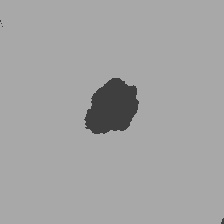

In [ ]:
test = os.listdir(benigne_segmentirane_putanje)
check = cv2.imread(os.path.join(benigne_segmentirane_putanje, test[0]))
cv2_imshow(check)

In [ ]:
from PIL import Image

def load_images_from_folder(folder_path):
    images = []
    for filename in os.listdir(folder_path):
        img = Image.open(os.path.join(folder_path, filename))
        img = img.convert('RGB')
        if img is not None:
            images.append(img)
    return images

benign_images = load_images_from_folder(benigne_segmentirane_putanje)
malignant_images = load_images_from_folder(maligne_segmentirane_putanje)

# Ekstrakcija značajki iz učitanih slika
benign_feature = extract_vector(benign_images)
malignant_feature = extract_vector(malignant_images)

1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━

In [ ]:
benign_images2 = load_images_from_folder(benign_path)
malignant_images2 = load_images_from_folder(malignant_path)

benign_feature2 = extract_vector(benign_images2)
malignant_feature2 = extract_vector(malignant_images2)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━

In [ ]:
print(f'Benigne značajke: {benign_feature}')
print(f'Maligne značajke: {malignant_feature}')

Benigne značajke: [[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]]
Maligne značajke: [[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]]


In [ ]:
print(f'Benigne značajke (original): {benign_feature2}')
print(f'Maligne značajke (original): {malignant_feature2}')

Benigne značajke (original): [[0.        0.        0.        ... 0.        0.        0.       ]
 [0.        0.        0.        ... 0.        0.        0.       ]
 [0.        0.        0.        ... 0.        0.        0.       ]
 ...
 [0.        5.3108177 0.        ... 0.        0.        0.       ]
 [0.        0.        0.        ... 0.        0.        0.       ]
 [0.        0.        0.        ... 0.        0.        0.       ]]
Maligne značajke (original): [[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]]


Klasteriranje

---



<Axes: title={'center': 'Benigne segmentirane'}, xlabel='PC1', ylabel='PC2'>

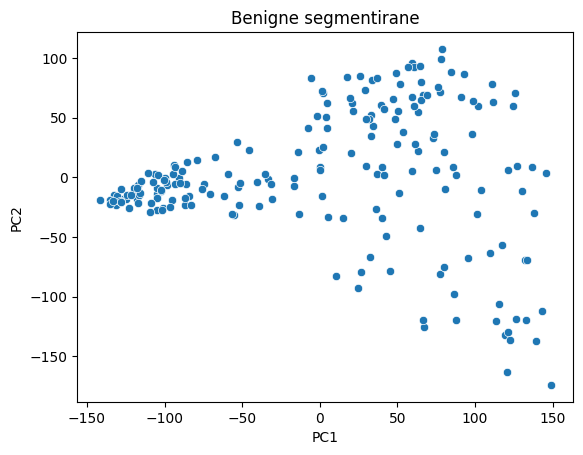

In [ ]:
from sklearn.decomposition import PCA

# Primjena PCA
pca = PCA(n_components=2)
benign_pca = pca.fit_transform(benign_feature)

df = pd.DataFrame(benign_pca, columns=['PC1', 'PC2'])

plt.title('Benigne segmentirane')
sns.scatterplot(data=df, x='PC1', y='PC2')

<Axes: title={'center': 'Maligne segmentirane'}, xlabel='PC1', ylabel='PC2'>

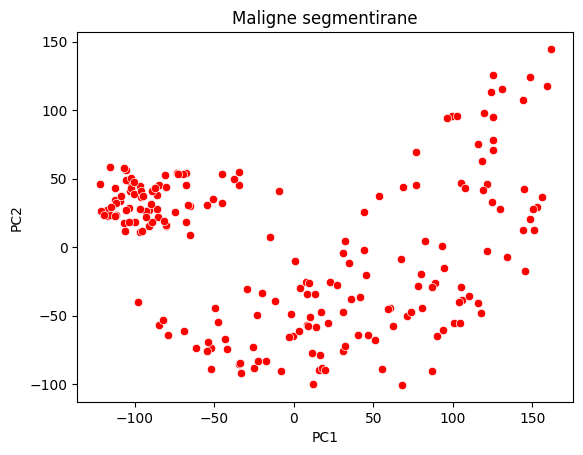

In [ ]:
pca = PCA(n_components=2)
malignant_pca = pca.fit_transform(malignant_feature)

df = pd.DataFrame(malignant_pca, columns=['PC1', 'PC2'])

plt.title('Maligne segmentirane')
sns.scatterplot(data=df, x='PC1', y='PC2', color='red')

In [ ]:
import plotly.express as px

# Spajanje benignih i malignih značajki
all_features = np.concatenate((benign_feature, malignant_feature), axis=0)

pca = PCA(n_components=2)
pca_result = pca.fit_transform(all_features)

# Razdvajanje PCA rezultata natrag na benigne i maligne značajke
benign_pca = pca_result[:len(benign_feature)]
malignant_pca = pca_result[len(benign_feature):]

data = pd.DataFrame(np.vstack((benign_pca, malignant_pca)), columns=['PC1', 'PC2'])
data['Label'] = ['Benign'] * len(benign_pca) + ['Malignant'] * len(malignant_pca)

fig = px.scatter(
    data,
    x='PC1',
    y='PC2',
    color='Label',
    title='PCA of Features - Segmented Image',
    labels={'PC1': 'Principal Component 1', 'PC2': 'Principal Component 2'},
    opacity=0.7,
    color_discrete_map={'Benign': 'blue', 'Malignant': 'red'}
)
fig.show()


<Axes: title={'center': 'Benigne originalne'}, xlabel='PC1', ylabel='PC2'>

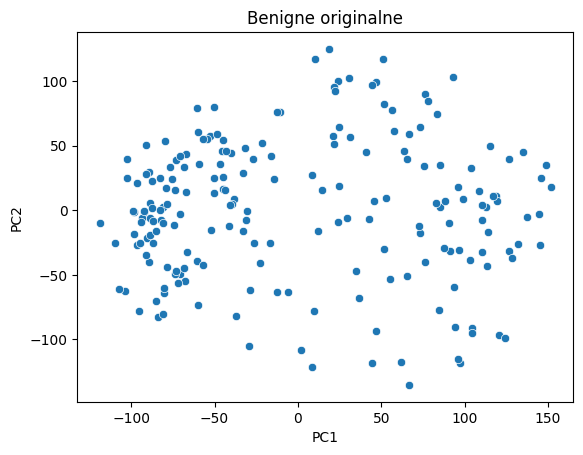

In [ ]:
pca = PCA(n_components=2)
benign_pca2 = pca.fit_transform(benign_feature2)

df = pd.DataFrame(benign_pca2, columns=['PC1', 'PC2'])

plt.title('Benigne originalne')
sns.scatterplot(data=df, x='PC1', y='PC2')

<Axes: title={'center': 'Maligne originalne'}, xlabel='PC1', ylabel='PC2'>

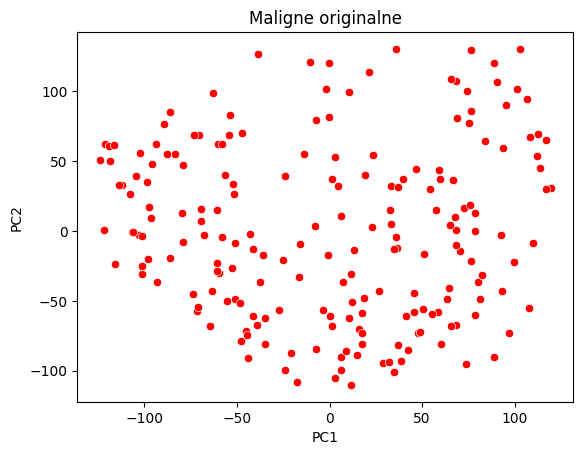

In [ ]:
pca = PCA(n_components=2)
malignant_pca2 = pca.fit_transform(malignant_feature2)

df = pd.DataFrame(malignant_pca2, columns=['PC1', 'PC2'])

plt.title('Maligne originalne')
sns.scatterplot(data=df, x='PC1', y='PC2', color='red')

In [ ]:
all_features = np.concatenate((benign_feature2, malignant_feature2), axis=0)

pca = PCA(n_components=2)
pca_result = pca.fit_transform(all_features)

benign_pca2 = pca_result[:len(benign_feature2)]
malignant_pca2 = pca_result[len(benign_feature2):]

data = pd.DataFrame(np.vstack((benign_pca2, malignant_pca2)), columns=['PC1', 'PC2'])
data['Label'] = ['Benign'] * len(benign_pca2) + ['Malignant'] * len(malignant_pca2)

fig = px.scatter(
    data,
    x='PC1',
    y='PC2',
    color='Label',
    title='PCA of Features - Original Images',
    labels={'PC1': 'Principal Component 1', 'PC2': 'Principal Component 2'},
    opacity=0.7,
    color_discrete_map={'Benign': 'blue', 'Malignant': 'red'}
)
fig.show()


Provjera normalnosti distribucije

---

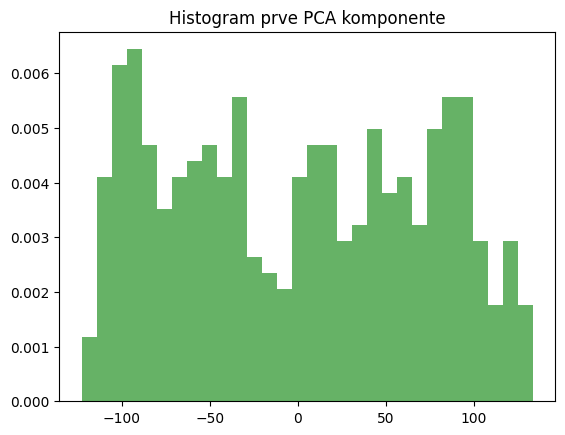

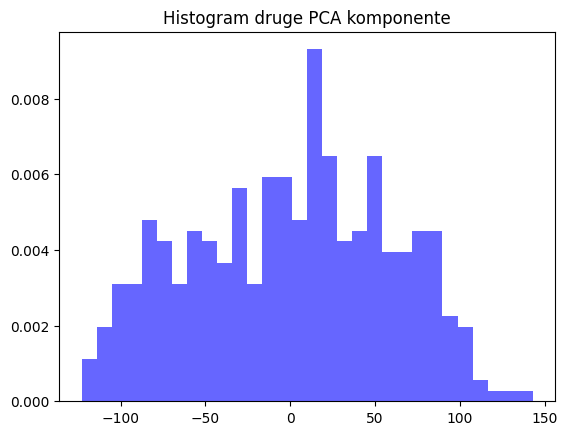

In [ ]:
# Histogram za prvu PCA komponentu
plt.hist(pca_result[:, 0], bins=30, density=True, alpha=0.6, color='g')
plt.title("Histogram prve PCA komponente")
plt.show()

# Histogram za drugu PCA komponentu
plt.hist(pca_result[:, 1], bins=30, density=True, alpha=0.6, color='b')
plt.title("Histogram druge PCA komponente")
plt.show()


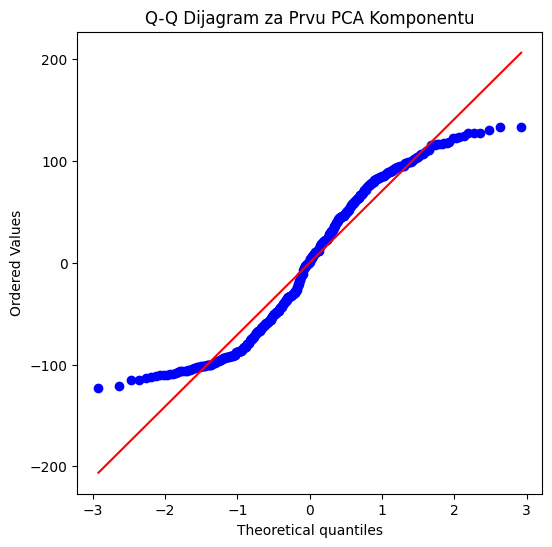

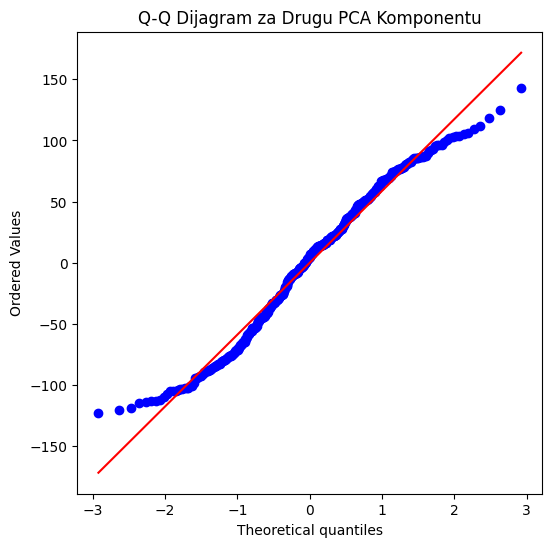

In [ ]:
import scipy.stats as stats

# Q-Q dijagram za prvu PCA komponentu
plt.figure(figsize=(6, 6))
stats.probplot(pca_result[:, 0], dist="norm", plot=plt)
plt.title("Q-Q Dijagram za Prvu PCA Komponentu")
plt.show()

# Q-Q dijagram za drugu PCA komponentu
plt.figure(figsize=(6, 6))
stats.probplot(pca_result[:, 1], dist="norm", plot=plt)
plt.title("Q-Q Dijagram za Drugu PCA Komponentu")
plt.show()


In [ ]:
from scipy.stats import shapiro
import matplotlib.pyplot as plt

# Testiranje normalnosti za prvu PCA komponentu
stat_pc1, p_value_pc1 = shapiro(pca_result[:, 0])
stat_pc2, p_value_pc2 = shapiro(pca_result[:, 1])

print(f'Shapiro-Wilk Test za PC1:\nStatistika: {stat_pc1}, P-vrijednost: {p_value_pc1}')
print(f'Shapiro-Wilk Test za PC2:\nStatistika: {stat_pc2}, P-vrijednost: {p_value_pc2}')

if p_value_pc1 < 0.05:
    print("Prva PCA komponenta nije normalno distribuirana.")
else:
    print("Prva PCA komponenta je normalno distribuirana.")

if p_value_pc2 < 0.05:
    print("Druga PCA komponenta nije normalno distribuirana.")
else:
    print("Druga PCA komponenta je normalno distribuirana.")


Shapiro-Wilk Test za PC1:
Statistika: 0.9448637991607451, P-vrijednost: 4.839163643519997e-11
Shapiro-Wilk Test za PC2:
Statistika: 0.9799549798359354, P-vrijednost: 2.4089049387615257e-05
Prva PCA komponenta nije normalno distribuirana.
Druga PCA komponenta nije normalno distribuirana.


In [ ]:
def manual_silhouette_score(X, labels):
    n_samples = len(X)
    silhouette_values = np.zeros(n_samples)

    # Izračunavanje parnih udaljenosti između uzoraka
    distances = np.zeros((n_samples, n_samples))
    for i in range(n_samples):
        for j in range(n_samples):
            distances[i, j] = np.linalg.norm(X[i] - X[j])

    for i in range(n_samples):
        # Izračunavanje prosječne udaljenosti do drugih uzoraka u istom klasteru (a_i)
        cluster_label = labels[i]
        cluster_indices = np.where(labels == cluster_label)[0]
        a_i = np.mean(distances[i, cluster_indices])

        # Izračunavanje prosječne udaljenosti do uzoraka u drugim klasterima (b_i)
        b_i = np.min([np.mean(distances[i, np.where(labels == other_label)[0]]) for other_label in np.unique(labels) if other_label != cluster_label])

        # Izračunavanje silhouette vrijednosti za uzorak i
        silhouette_values[i] = (b_i - a_i) / max(a_i, b_i)

    silhouette_score = np.mean(silhouette_values)
    return silhouette_score


def purity_score(y_true, y_pred):
    # Pretvaranje oznaka u cijele brojeve
    y_true_int = np.asarray(y_true, dtype=int)
    y_pred_int = np.asarray(y_pred, dtype=int)

    # Izračunavanje matrice kontingencije
    contingency_matrix = np.zeros((len(np.unique(y_true_int)), len(np.unique(y_pred_int))))
    for i, j in zip(y_true_int, y_pred_int):
        contingency_matrix[i, j] += 1

    purity = np.sum(np.amax(contingency_matrix, axis=0)) / np.sum(contingency_matrix)

    return purity

# Kombiniranje značajki i odgovarajućih oznaka
all_features = np.concatenate([benign_feature, malignant_feature])
all_labels = np.concatenate([np.zeros(len(benign_feature)), np.ones(len(malignant_feature))])

cluster_labels, cluster_centers = self_kmeans(all_features, n_clusters=2)

silhouette = manual_silhouette_score(all_features, cluster_labels)

purity = purity_score(all_labels, cluster_labels)

print(f'''
SEGMENTED IMAGES CLUSTER
------------------------
Cluster Purity: {purity}
Silhouette Score: {silhouette}
      ''')


SEGMENTED IMAGES CLUSTER
------------------------
Cluster Purity: 0.55
Silhouette Score: 0.11304236957322435
      


In [ ]:
all_features = np.concatenate([benign_feature2, malignant_feature2])
all_labels = np.concatenate([np.zeros(len(benign_feature2)), np.ones(len(malignant_feature2))])

cluster_labels, cluster_centers = self_kmeans(all_features, n_clusters=2)

silhouette = manual_silhouette_score(all_features, cluster_labels)

purity = purity_score(all_labels, cluster_labels)

print(f'''
ORIGINAL IMAGES CLUSTER
------------------------
Cluster Purity: {purity}
Silhouette Score: {silhouette}
      ''')


ORIGINAL IMAGES CLUSTER
------------------------
Cluster Purity: 0.6125
Silhouette Score: 0.06348873574101029
      


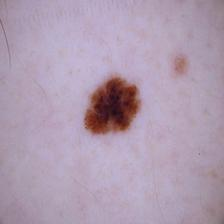


  Actual Label: Benign
  Cluster Label: 0
  


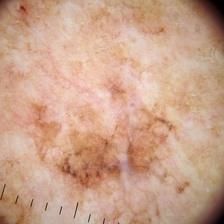


  Actual Label: Malignant
  Cluster Label: 1
  


In [ ]:
def load_and_display_image(image_path):
    image = cv2.imread(image_path)
    cv2_imshow(image)
    cv2.waitKey(0)
    cv2.destroyAllWindows()
    return image


# Pronalaženje indeksa prve slike u svakom klasteru
first_benign_index = np.where(cluster_labels == 0)[0][0]
first_malignant_index = np.where(cluster_labels == 1)[0][0]

# Dohvaćanje naziva datoteka prvih slika u svakom klasteru
first_benign_filename = benign_files[first_benign_index]
first_malignant_filename = malignant_files[first_malignant_index]

first_benign_image = load_and_display_image(os.path.join(benign_path, first_benign_filename))
print(
  f'''
  Actual Label: Benign
  Cluster Label: {cluster_labels[first_benign_index]}
  '''
)

first_malignant_image = load_and_display_image(os.path.join(malignant_path, first_malignant_filename))
print(
  f'''
  Actual Label: Malignant
  Cluster Label: {cluster_labels[first_malignant_index]}
  '''
)

Validacija sa CNN

---



In [ ]:
def load_images(directory_path):
    images = []
    for filename in os.listdir(directory_path):
        if filename.endswith(".jpg") or filename.endswith(".png"):
            image_path = os.path.join(directory_path, filename)
            image = cv2.imread(image_path)
            image = cv2.resize(image, (224, 224))
            images.append(image)
    return images

benign_images = load_images(benign_path)
malignant_images = load_images(malignant_path)
benign_segmented_images = load_images(benigne_segmentirane_putanje)
malignant_segmented_images = load_images(maligne_segmentirane_putanje)

X_original = np.concatenate((benign_images, malignant_images))
X_segmented = np.concatenate((benign_segmented_images, malignant_segmented_images))
y_original = np.concatenate((np.zeros(len(benign_images)), np.ones(len(malignant_images))))
y_segmented = np.concatenate((np.zeros(len(benign_segmented_images)), np.ones(len(malignant_segmented_images))))

In [ ]:
print(len(X_original))
print(len(X_segmented))

print(len(y_original))
print(len(y_segmented))

400
400
400
400


In [ ]:
X_original[0].shape

(224, 224, 3)

In [ ]:
y_original.shape

(400,)

In [ ]:
from sklearn.model_selection import train_test_split

x_train_original, x_test_original, y_train_original, y_test_original = train_test_split(X_original, y_original, test_size=0.2, random_state=42)
x_train_segmented, x_test_segmented, y_train_segmented, y_test_segmented = train_test_split(X_segmented, y_segmented, test_size=0.2, random_state=42)

print(f'x train original: {len(x_train_original)}, x test original: {len(x_test_original)}, y train original: {len(y_train_original)}, y test original: {len(y_test_original)}')
print(f'x train segmented: {len(x_train_segmented)}, x test segmented: {len(x_test_segmented)}, y train segmented: {len(y_train_segmented)}, y test segmented: {len(y_test_segmented)}')

x train original: 320, x test original: 80, y train original: 320, y test original: 80
x train segmented: 320, x test segmented: 80, y train segmented: 320, y test segmented: 80


In [ ]:
import tensorflow as tf
from tensorflow.keras.layers import Dense, BatchNormalization, Flatten

model = tf.keras.models.Sequential([
    base_model,
    BatchNormalization(),
    Flatten(),
    Dense(512, activation = 'relu'),
    Dense(1, activation='sigmoid')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224 (Functional)    │ (None, 7, 7, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 7, 7, 1280)          │           5,120 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 62720)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 512)                 │      32,113,152 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │             513 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 34,376,769 (131.14 MB)

 Trainable params: 32,116,225 (122.51 MB)

 Non-trainable params: 2,260,544 (8.62 MB)

In [ ]:
model.compile(
    loss = 'binary_crossentropy',
    optimizer = tf.optimizers.Adam(),
    metrics = ['accuracy']
)

In [ ]:
y_train_original_reshaped = np.expand_dims(y_train_original, axis=-1)
y_test_original_reshaped = np.expand_dims(y_test_original, axis=-1)

ori = model.fit(
    x_train_original, y_train_original_reshaped,
    epochs = 30,
    validation_data = (x_test_original, y_test_original_reshaped),
    verbose = 2
)

Epoch 1/30
10/10 - 23s - 2s/step - accuracy: 0.6531 - loss: 8.5316 - val_accuracy: 0.4500 - val_loss: 23.4846
Epoch 2/30
10/10 - 4s - 404ms/step - accuracy: 0.8219 - loss: 1.9741 - val_accuracy: 0.6500 - val_loss: 10.9346
Epoch 3/30
10/10 - 1s - 56ms/step - accuracy: 0.9312 - loss: 0.5153 - val_accuracy: 0.5625 - val_loss: 6.3339
Epoch 4/30
10/10 - 0s - 43ms/step - accuracy: 0.9750 - loss: 0.0500 - val_accuracy: 0.7125 - val_loss: 3.6733
Epoch 5/30
10/10 - 0s - 44ms/step - accuracy: 0.9937 - loss: 0.0264 - val_accuracy: 0.6250 - val_loss: 3.8717
Epoch 6/30
10/10 - 1s - 61ms/step - accuracy: 0.9969 - loss: 0.0039 - val_accuracy: 0.6875 - val_loss: 2.9992
Epoch 7/30
10/10 - 1s - 50ms/step - accuracy: 0.9937 - loss: 0.0126 - val_accuracy: 0.6750 - val_loss: 2.8431
Epoch 8/30
10/10 - 1s - 60ms/step - accuracy: 1.0000 - loss: 0.0044 - val_accuracy: 0.7250 - val_loss: 2.4004
Epoch 9/30
10/10 - 1s - 55ms/step - accuracy: 0.9969 - loss: 0.0043 - val_accuracy: 0.7500 - val_loss: 1.9625
Epoch 10

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.7898 - loss: 2.0997
3/3 ━━━━━━━━━━━━━━━━━━━━ 6s 1s/step
Performanse na originalnim slikama - Gubitak: 2.0249264240264893, Točnost: 0.7749999761581421
Matrica konfuzije:


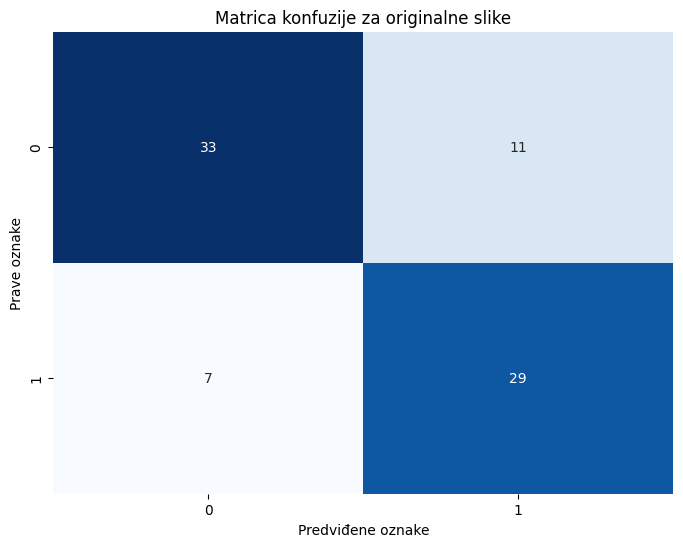

In [ ]:
from sklearn.metrics import confusion_matrix

y_test_original = y_test_original.reshape(-1, 1)

# Evaluacija performansi na originalnim slikama
loss_original, accuracy_original = model.evaluate(x_test_original, y_test_original)

# Predviđanje oznaka za originalne slike
y_pred_original = model.predict(x_test_original)
y_pred_original_binary = (y_pred_original > 0.5).astype(int)  # Pretvaranje vjerojatnosti u binarne predikcije

conf_matrix_original = confusion_matrix(y_test_original, y_pred_original_binary)

print(f"Performanse na originalnim slikama - Gubitak: {loss_original}, Točnost: {accuracy_original}")
print("Matrica konfuzije:")

plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_original, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.xlabel("Predviđene oznake")
plt.ylabel("Prave oznake")
plt.title("Matrica konfuzije za originalne slike")
plt.show()

In [ ]:
y_train_segmented_reshaped = np.expand_dims(y_train_segmented, axis=-1)
y_test_segmented_reshaped = np.expand_dims(y_test_segmented, axis=-1)

seg = model.fit(
    x_train_segmented, y_train_segmented_reshaped,
    epochs = 30,
    validation_data = (x_test_segmented, y_test_segmented_reshaped),
    verbose = 2
)

Epoch 1/30
10/10 - 1s - 71ms/step - accuracy: 0.6531 - loss: 2.4964 - val_accuracy: 0.6500 - val_loss: 3.1140
Epoch 2/30
10/10 - 1s - 53ms/step - accuracy: 0.8562 - loss: 0.4021 - val_accuracy: 0.8000 - val_loss: 1.3062
Epoch 3/30
10/10 - 1s - 60ms/step - accuracy: 0.9375 - loss: 0.1988 - val_accuracy: 0.7250 - val_loss: 0.9837
Epoch 4/30
10/10 - 1s - 76ms/step - accuracy: 0.9719 - loss: 0.0961 - val_accuracy: 0.7125 - val_loss: 0.9658
Epoch 5/30
10/10 - 1s - 104ms/step - accuracy: 0.9906 - loss: 0.0549 - val_accuracy: 0.7375 - val_loss: 0.8261
Epoch 6/30
10/10 - 1s - 61ms/step - accuracy: 0.9937 - loss: 0.0297 - val_accuracy: 0.7625 - val_loss: 0.8317
Epoch 7/30
10/10 - 1s - 68ms/step - accuracy: 0.9969 - loss: 0.0130 - val_accuracy: 0.7750 - val_loss: 0.7959
Epoch 8/30
10/10 - 0s - 43ms/step - accuracy: 0.9969 - loss: 0.0221 - val_accuracy: 0.7500 - val_loss: 0.9292
Epoch 9/30
10/10 - 0s - 42ms/step - accuracy: 0.9969 - loss: 0.0145 - val_accuracy: 0.7750 - val_loss: 0.7950
Epoch 10/

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - accuracy: 0.8094 - loss: 0.8543
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
Performanse na segmentiranim slikama - Gubitak: 0.8998540639877319, Točnost: 0.7749999761581421
Matrica konfuzije:


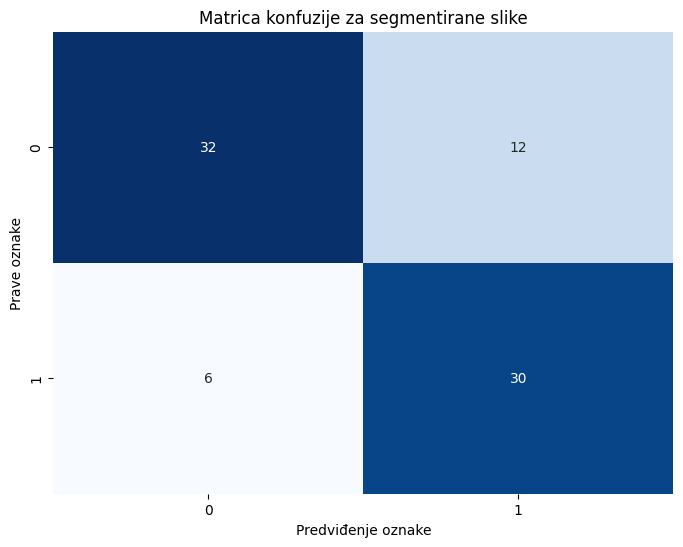

In [ ]:
loss_segmented, accuracy_segmented = model.evaluate(x_test_segmented, y_test_segmented.reshape(-1, 1))

y_pred_segmented = model.predict(x_test_segmented)
y_pred_segmented_binary = (y_pred_segmented > 0.5).astype(int)  #

conf_matrix_segmented = confusion_matrix(y_test_segmented, y_pred_segmented_binary)

print(f"Performanse na segmentiranim slikama - Gubitak: {loss_segmented}, Točnost: {accuracy_segmented}")
print("Matrica konfuzije:")

plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_segmented, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.xlabel("Predviđenje oznake")
plt.ylabel("Prave oznake")
plt.title("Matrica konfuzije za segmentirane slike")
plt.show()

DBSCAN algoritam

---

In [ ]:
from sklearn.cluster import DBSCAN

In [ ]:
train_data_path = '/content/drive/MyDrive/SU/Projekt/melanom/train'
benign_path = train_data_path + '/Benign'
malignant_path = train_data_path + '/Malignant'
test_data_path = '/content/drive/MyDrive/SU/Projekt/melanom/test'
benign_test_path = test_data_path + '/Benign'
malignant_test_path = test_data_path + '/Malignant'

print(len(os.listdir(benign_path)))
print(len(os.listdir(malignant_path)))

200
200


Ekstrakcija značajki

---


In [ ]:
# Ekstrakcija značajki s MobileNetV2
base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
for layer in base_model.layers:
    layer.trainable = False

# Ekstrakcija značajki za benigne slike
benign_features = []
for img in benign_images:
    x = image.img_to_array(img)
    x = preprocess_input(np.expand_dims(x, axis=0))
    feature = base_model.predict(x)
    benign_features.append(feature.flatten())
benign_features = np.array(benign_features)

# Ekstrakcija značajki za maligne slike
malignant_features = []
for img in malignant_images:
    x = image.img_to_array(img)
    x = preprocess_input(np.expand_dims(x, axis=0))
    feature = base_model.predict(x)
    malignant_features.append(feature.flatten())
malignant_features = np.array(malignant_features)

# Spajanje značajki
all_features = np.vstack((benign_features, malignant_features))

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━

In [ ]:
from sklearn.preprocessing import StandardScaler

# Standardizacija i PCA
scaler = StandardScaler()
features_scaled = scaler.fit_transform(all_features)

pca = PCA(n_components=2)
features_pca = pca.fit_transform(features_scaled)

In [ ]:
# PCA za benigne značajke
pca_benign = PCA(n_components=2)
benign_pca2 = pca_benign.fit_transform(benign_features)
benign_df = pd.DataFrame(benign_pca2, columns=['PC1', 'PC2'])

# PCA za maligne značajke
pca_malignant = PCA(n_components=2)
malignant_pca2 = pca_malignant.fit_transform(malignant_features)
malignant_df = pd.DataFrame(malignant_pca2, columns=['PC1', 'PC2'])

# PCA za sve značajke zajedno
pca_df = pd.DataFrame(features_pca, columns=['PC1', 'PC2'])
pca_df['Label'] = ['Benign'] * len(benign_features) + ['Malignant'] * len(malignant_features)

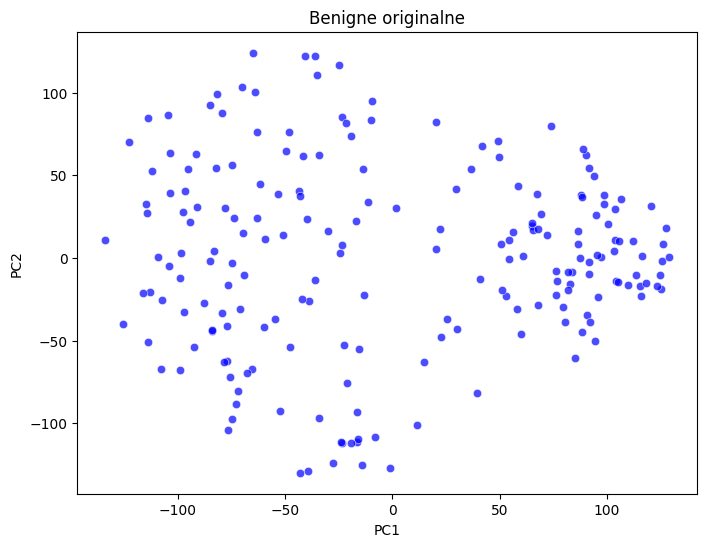

In [ ]:
# Vizualizacija 1: PCA za benigne originalne značajke
plt.figure(figsize=(8, 6))
sns.scatterplot(data=benign_df, x='PC1', y='PC2', color='blue', alpha=0.7)
plt.title('Benigne originalne')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.show()

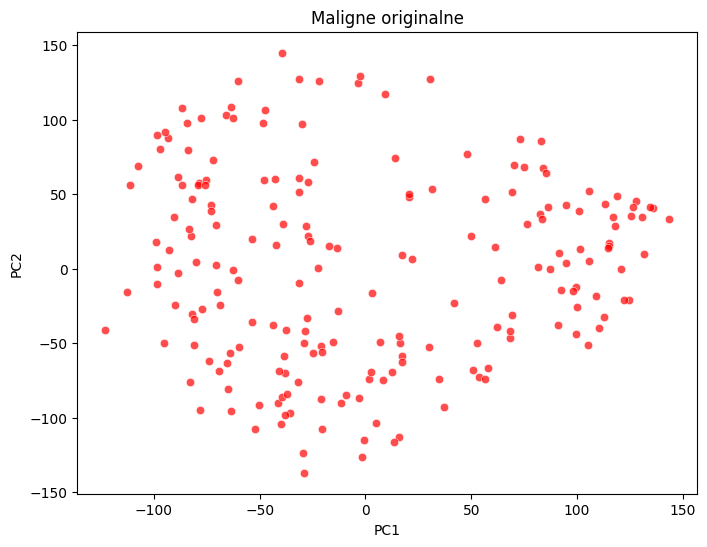

In [ ]:
# Vizualizacija 2: PCA za maligne originalne značajke
plt.figure(figsize=(8, 6))
sns.scatterplot(data=malignant_df, x='PC1', y='PC2', color='red', alpha=0.7)
plt.title('Maligne originalne')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.show()

In [ ]:
fig_all = px.scatter(
    pca_df,
    x='PC1',
    y='PC2',
    color='Label',
    title='PCA of All Features',
    labels={'PC1': 'Principal Component 1', 'PC2': 'Principal Component 2'},
    opacity=0.7,
    color_discrete_map={'Benign': 'blue', 'Malignant': 'red'}
)
fig_all.show()

In [ ]:
# Modificirani grid search za DBSCAN parametre
eps_range = np.arange(5, 50, 5)  # Povećani raspon za eps
min_samples_range = range(3, 200)  # Prilagođeni raspon za min_samples
best_score = -1
best_params = None

for eps in eps_range:
    for min_samples in min_samples_range:
        dbscan = DBSCAN(eps=eps, min_samples=min_samples)
        labels = dbscan.fit_predict(features_pca)

        # Provjera da imamo barem 2 klastera
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        if n_clusters < 2:
            continue

        # Provjera da nemamo previše šuma (npr. max 20% točaka)
        n_noise = list(labels).count(-1)
        if n_noise > len(features_pca) * 0.2:
            continue

        try:
            score = silhouette_score(features_pca, labels)
            if score > best_score:
                best_score = score
                best_params = (eps, min_samples)
        except:
            continue

if best_params is None:
    print("Nije pronađena dobra kombinacija parametara, postavljam default vrijednosti")
    best_params = (30, 5)  # Default vrijednosti
else:
    print(f"Best parameters: eps={best_params[0]}, min_samples={best_params[1]}")

Best parameters: eps=30, min_samples=64


In [ ]:
dbscan = DBSCAN(eps=best_params[0], min_samples=best_params[1])
labels = dbscan.fit_predict(features_pca)

data = pd.DataFrame(features_pca, columns=['PC1', 'PC2'])
data['Cluster'] = labels

data['Cluster_Label'] = data['Cluster'].apply(
    lambda x: 'Benign' if x == 0 else ('Malignant' if x == 1 else 'Noise')
)

fig = px.scatter(
    data,
    x='PC1',
    y='PC2',
    color='Cluster_Label',
    title='PCA of Features - DBSCAN Clustering',
    labels={'PC1': 'Principal Component 1', 'PC2': 'Principal Component 2'},
    opacity=0.7,
    color_discrete_map={
        'Benign': 'blue',
        'Malignant': 'red',
        'Noise': 'gray'
    }
)

fig.show()


In [ ]:
# Evaluacija klastera
true_labels = np.array([0]*len(benign_features) + [1]*len(malignant_features))

# Silhouette score
silhouette = silhouette_score(features_pca, cluster_labels) if len(np.unique(cluster_labels)) > 1 else 0

# Purity score
contingency_matrix = pd.crosstab(true_labels, cluster_labels)
purity = np.sum(np.max(contingency_matrix, axis=0)) / np.sum(contingency_matrix.values)

print(f'Silhouette Score: {silhouette:.3f}')
print(f'Purity Score: {purity:.3f}')

Silhouette Score: 0.317
Purity Score: 0.613


In [ ]:
# Priprema podataka za CNN
X = []
y = []

for img in benign_images:
    X.append(image.img_to_array(img))
    y.append(0)

for img in malignant_images:
    X.append(image.img_to_array(img))
    y.append(1)

X = np.array(X)
y = np.array(y)

# Train-test split
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.layers import Dense, Flatten, BatchNormalization

# CNN model
model = tf.keras.models.Sequential([
    base_model,
    BatchNormalization(),
    Flatten(),
    Dense(512, activation='relu'),
    Dense(1, activation='sigmoid')
])

model.compile(
    loss='binary_crossentropy',
    optimizer=tf.optimizers.Adam(),
    metrics=['accuracy']
)

# Treniranje modela
history = model.fit(
    X_train, y_train,
    epochs=30,
    validation_data=(X_test, y_test),
    batch_size=32
)

Epoch 1/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 14s 580ms/step - accuracy: 0.5761 - loss: 12.5860 - val_accuracy: 0.6750 - val_loss: 2.1259
Epoch 2/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 68ms/step - accuracy: 0.7664 - loss: 0.9234 - val_accuracy: 0.7625 - val_loss: 0.9909
Epoch 3/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 61ms/step - accuracy: 0.9122 - loss: 0.2558 - val_accuracy: 0.7375 - val_loss: 1.2725
Epoch 4/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 55ms/step - accuracy: 0.9557 - loss: 0.1478 - val_accuracy: 0.7625 - val_loss: 0.9660
Epoch 5/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 53ms/step - accuracy: 0.9817 - loss: 0.0617 - val_accuracy: 0.7375 - val_loss: 1.0439
Epoch 6/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 59ms/step - accuracy: 0.9957 - loss: 0.0293 - val_accuracy: 0.7625 - val_loss: 1.0120
Epoch 7/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 58ms/step - accuracy: 1.0000 - loss: 0.0132 - val_accuracy: 0.7250 - val_loss: 1.0846
Epoch 8/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 53ms/step - accuracy: 1.0000 - loss: 0.0154 - val_accuracy: 0.7750 

3/3 ━━━━━━━━━━━━━━━━━━━━ 7s 1s/step


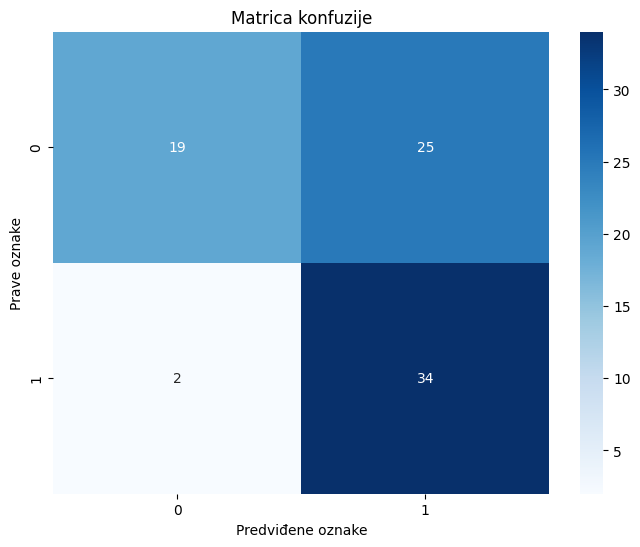

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.6906 - loss: 1.9158
Test accuracy: 0.663
Test loss: 1.863


In [ ]:
# Evaluacija CNN modela
from sklearn.metrics import confusion_matrix
import seaborn as sns

y_pred = (model.predict(X_test) > 0.5).astype(int)
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Matrica konfuzije')
plt.ylabel('Prave oznake')
plt.xlabel('Predviđene oznake')
plt.show()

# Ispis metrika
test_loss, test_accuracy = model.evaluate(X_test, y_test)
print(f'Test accuracy: {test_accuracy:.3f}')
print(f'Test loss: {test_loss:.3f}')

In [ ]:
from scipy.stats import wilcoxon

kmeans_scores = np.array([0.063488])
dbscan_scores = np.array([0.317])

# Izvođenje Wilcoxon Signed-Rank testa
stat, p_value = wilcoxon(kmeans_scores, dbscan_scores)

print(f'Wilcoxon Signed-Rank test:')
print(f'Statistika: {stat}')
print(f'P-vrijednost: {p_value}')

if p_value < 0.05:
    print("Postoji značajna razlika između K-Means i DBSCAN.")
else:
    print("Nema značajne razlike između K-Means i DBSCAN.")


Wilcoxon Signed-Rank test:
Statistika: 0.0
P-vrijednost: 1.0
Nema značajne razlike između K-Means i DBSCAN.
